# Import Library & Prepare Data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from yellowbrick.cluster import KElbowVisualizer

In [ ]:
# Read the data
df = pd.read_csv("vw_customer_analytical_base.csv")

df.head()

,customer_unique_id,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,159.544132,-4.132905,0.084567
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,162.533715,-4.248125,0.304892
2,0000f46a3911fa3c0805444483337064,1,86.22,585.121493,-1.389734,0.199722
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,369.146053,-11.108970,0.404172
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,336.176597,-7.035463,0.085784


# Exploratory Data Analysis (EDA)

In [ ]:
# Check information each columns
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93357 entries, 0 to 93356
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_unique_id  93357 non-null  object 
 1   frequency           93357 non-null  int64  
 2   lifetime_spend      93357 non-null  float64
 3   recency_days        93357 non-null  float64
 4   avg_delivery_delay  93349 non-null  float64
 5   avg_freight_ratio   93357 non-null  float64
dtypes: float64(4), int64(1), object(1)
memory usage: 4.3+ MB


In [ ]:
# Impute missing values by mean of the columns
imputer = SimpleImputer(strategy="mean")
df["avg_delivery_delay"] = imputer.fit_transform(df['avg_delivery_delay'].values.reshape(-1, 1))

In [ ]:
# Check again for missing values
df.isna().sum()

,0
customer_unique_id,0
frequency,0
lifetime_spend,0
recency_days,0
avg_delivery_delay,0
avg_freight_ratio,0


In [ ]:
# Descriptive statistic for this data
df.describe()

,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio
count,93357.000000,93357.000000,93357.000000,93357.000000,93357.000000
mean,1.033420,165.198772,285.836849,-11.151066,0.208670
std,0.209099,226.314579,152.586141,10.139344,0.124869
min,1.000000,9.590000,48.374572,-146.016123,0.000000
25%,1.000000,63.060000,162.275567,-16.226840,0.116837
50%,1.000000,107.780000,266.986968,-11.738032,0.183370
75%,1.000000,182.560000,394.231111,-6.393403,0.274779
max,15.000000,13664.080000,743.293866,188.975081,0.955451


In [ ]:
# Select feature columns only
feature_columns = [col for col in df.columns if col != "customer_unique_id"]
feature_columns

['frequency',
 'lifetime_spend',
 'recency_days',
 'avg_delivery_delay',
 'avg_freight_ratio']

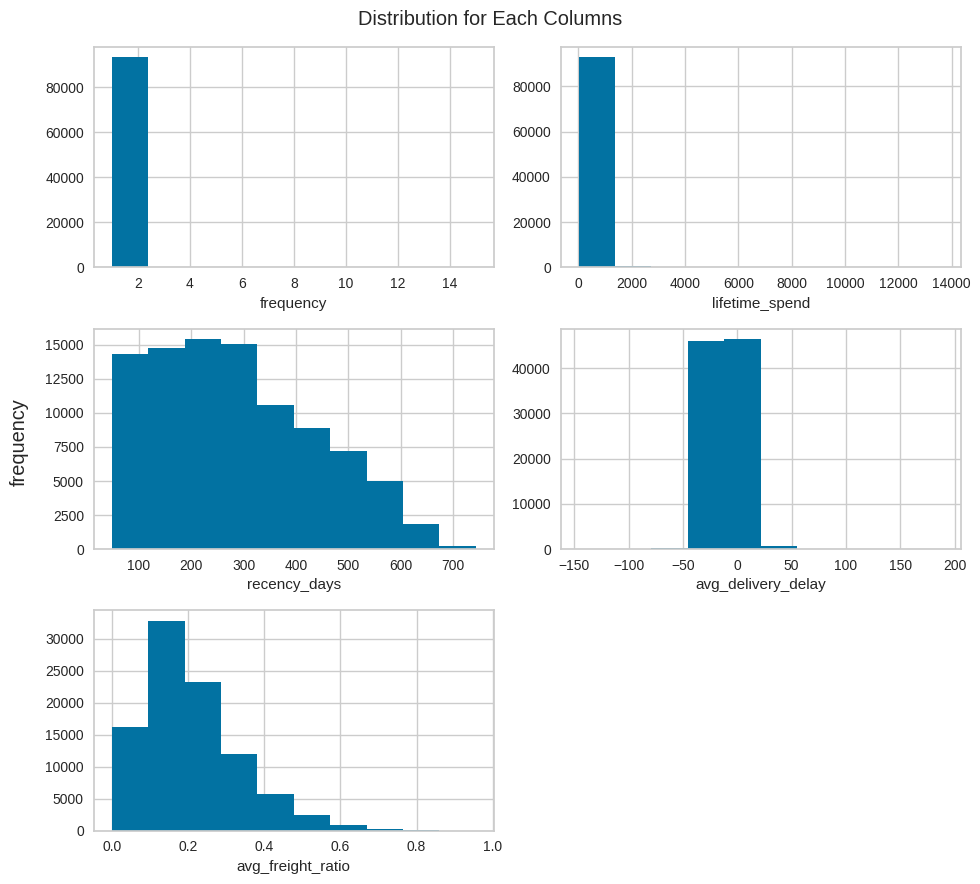

In [ ]:
# Histogram plot for each columns
fig, axes = plt.subplots(3, 2, figsize=(10, 9))

axes = axes.flatten()

for i, col in enumerate(feature_columns):
  ax = axes[i]

  ax.hist(df[col], log=False)
  ax.set_xlabel(col)

for j in range(5, len(axes)):
  fig.delaxes(axes[j])

fig.supylabel("frequency")
plt.suptitle("Distribution for Each Columns")

plt.tight_layout()
plt.show()

Looking at the histogram above, we can see that some features have an extreme skewness. To handle this problem, we can perform log transformation to that columns. For this case, only frequency and lifetime_spend columns will be transformed.

In [ ]:
# Log-trasformation
df_log = df.copy()

for col in ["frequency", "lifetime_spend"]:
  df_log[col] = np.log1p(df_log[col])

df_log.head()

,customer_unique_id,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio
0,0000366f3b9a7992bf8c76cfdf3221e2,0.693147,4.962145,159.544132,-4.132905,0.084567
1,0000b849f77a49e4a4ce2b2a4ca5be3f,0.693147,3.338967,162.533715,-4.248125,0.304892
2,0000f46a3911fa3c0805444483337064,0.693147,4.468434,585.121493,-1.389734,0.199722
3,0000f6ccb0745a6a4b88665a16c9f078,0.693147,3.798182,369.146053,-11.108970,0.404172
4,0004aac84e0df4da2b147fca70cf8255,0.693147,5.287711,336.176597,-7.035463,0.085784


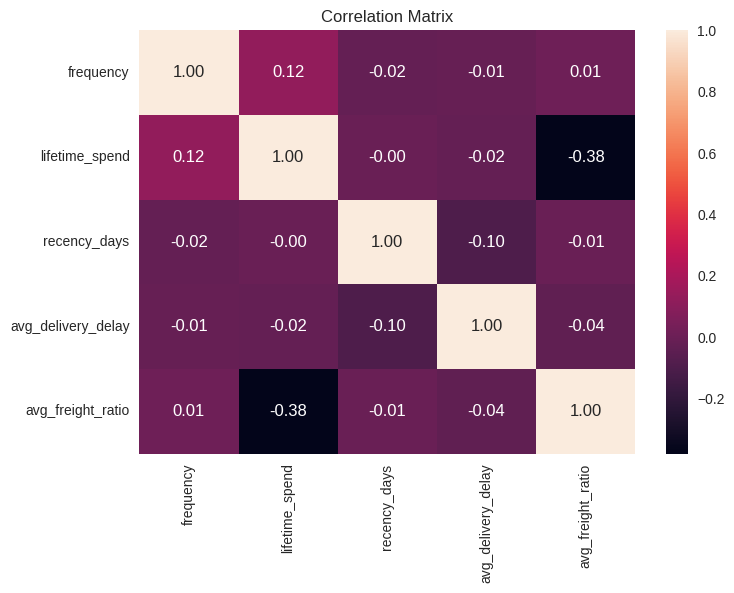

In [ ]:
# Correlation matrix
corr_matrix = df[feature_columns].corr()

sns.heatmap(corr_matrix, fmt=".2f", annot=True)
plt.title("Correlation Matrix")

plt.show()

# Clustering Using K-Means


In [ ]:
# Standardize the data
scaler = StandardScaler()

X = df_log[feature_columns]
X_scaled = scaler.fit_transform(X)


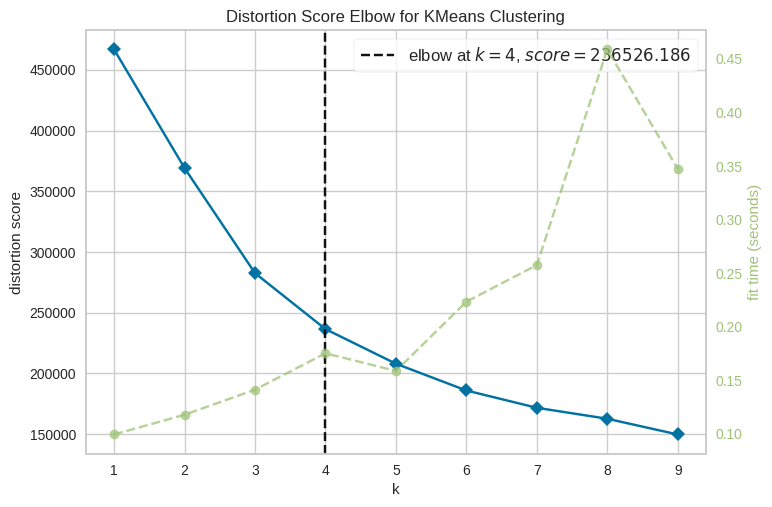

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# Find the best k using elbow method
model = KMeans(random_state=69)

visualizer = KElbowVisualizer(model, k=(1, 10))
visualizer.fit(X_scaled)

visualizer.show()

In [ ]:
# Clustering using K-Means
best_k = visualizer.elbow_value_

model = KMeans(n_clusters=best_k, random_state=69)
model.fit(X_scaled)

df["cluster"] = model.labels_
df.head()

,customer_unique_id,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio,cluster
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,159.544132,-4.132905,0.084567,2
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,162.533715,-4.248125,0.304892,0
2,0000f46a3911fa3c0805444483337064,1,86.22,585.121493,-1.389734,0.199722,3
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,369.146053,-11.108970,0.404172,0
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,336.176597,-7.035463,0.085784,2


In [ ]:
# Group data based on cluster
df_grouped = df.groupby("cluster")[feature_columns].mean()
df_grouped

,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio
cluster,,,,,
0,1.000000,56.386809,249.973833,-10.438062,0.347373
1,2.113888,308.588793,268.185244,-11.895383,0.216230
2,1.000000,236.722860,195.331029,-9.744075,0.133228
3,1.000000,160.152488,463.494411,-13.969235,0.170173


In [ ]:
# Mapping cluster into customer's category
persona_mapping = {
    0: "Low-Value (High Shipping)",
    1: "Loyal Champions",
    2: "Recent Promising Spenders",
    3: "Churned Customers"
}

df['customer_persona'] = df['cluster'].map(persona_mapping)

df.head()

,customer_unique_id,frequency,lifetime_spend,recency_days,avg_delivery_delay,avg_freight_ratio,cluster,customer_persona
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,159.544132,-4.132905,0.084567,2,Recent Promising Spenders
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,162.533715,-4.248125,0.304892,0,Low-Value (High Shipping)
2,0000f46a3911fa3c0805444483337064,1,86.22,585.121493,-1.389734,0.199722,3,Churned Customers
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,369.146053,-11.108970,0.404172,0,Low-Value (High Shipping)
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,336.176597,-7.035463,0.085784,2,Recent Promising Spenders


In [ ]:
# Export the data
df.to_csv("olist_customer_segments_powerbi.csv", index=False)